# 通用组合优化 · 四节点加权 MaxCut

QuantumBridge / 工业优化 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 小图 MaxCut 可执行案例，不等于图优化全部问题族或工业规模求解能力；没有性能或量子加速结论。

## 1. 原理与计算对象

四个节点划入两组，跨组边权之和为割值。令 $x_i=(1-Z_i)/2$，单条边是否被割为 $(1-Z_iZ_j)/2$。所以负割值是严格二次 Ising 代价：$H_C=-\sum w_{ij}(1-Z_iZ_j)/2$。
这一例确实是二次模型，成本 Pauli 阶数应为 2。通过原生一层 QAOA 生成候选，与所有 16 个划分的完全枚举比较；互补位串表示同一个无向割。

## 2. 实现步骤

1. 声明四节点五条带权边。
2. 枚举割划分、计算负割代价与精确最优。
3. 校验二次 Z 展开并优化 QAOA 参数。
4. 采样并恢复节点分组。
5. 报告最佳实际观测割、最优频率和成本差。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import optimization_case

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def maxcut_case():
    edges = [(0, 1, 1), (1, 2, 2), (2, 3, 1), (3, 0, 2), (0, 2, 0.5)]
    candidates = []
    for bits in labels(4):
        cut = sum(weight for a, b, weight in edges if bits[a] != bits[b])
        candidates.append(
            {
                "bitstring": bits,
                "partition0": [i for i, bit in enumerate(bits) if bit == "0"],
                "cut_weight": cut,
                "feasible": True,
                "objective": -cut,
                "penalized_cost": -cut,
            }
        )
    return optimization_case(
        "combinatorial",
        "industry",
        "Weighted four-node MaxCut",
        {
            "nodes": 4,
            "edges": edges,
            "objective": "minimize minus cut weight",
            "penalty": 0,
        },
        candidates,
    )


In [3]:
case = maxcut_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

bitstring,partition0,cut_weight,feasible,objective,penalized_cost
0000,"[0, 1, 2, 3]",0,True,0,0
0001,"[0, 1, 2]",3,True,-3,-3
0010,"[0, 1, 3]",3.5,True,-3.5,-3.5
0011,"[0, 1]",4.5,True,-4.5,-4.5
0100,"[0, 2, 3]",3,True,-3,-3
0101,"[0, 2]",6,True,-6,-6
0110,"[0, 3]",2.5,True,-2.5,-2.5
0111,[0],3.5,True,-3.5,-3.5
1000,"[1, 2, 3]",3.5,True,-3.5,-3.5
1001,"[1, 2]",2.5,True,-2.5,-2.5


improvement,expected_penalized_cost,gamma,beta
0,-3.25,0,0
1,-3.25,0,0.72498292
2,-3.6406203,0.78539816,0.96664389
3,-3.8777453,0.78539816,1.2083049
4,-3.9000981,1.5707963,0.96664389
5,-4.3760842,1.5707963,1.2083049
6,-4.6898281,2.3561945,1.2083049
7,-4.7963871,3.1415927,1.2083049


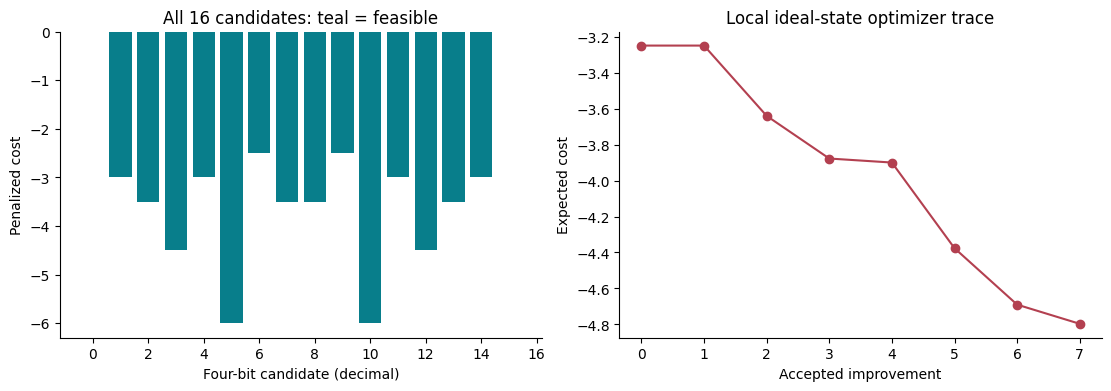

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
qaoa,4,25,1024,20261023


observable,estimate,standard_error,ideal_reference
qaoa,-4.7167969,0.045601396,-4.7963871


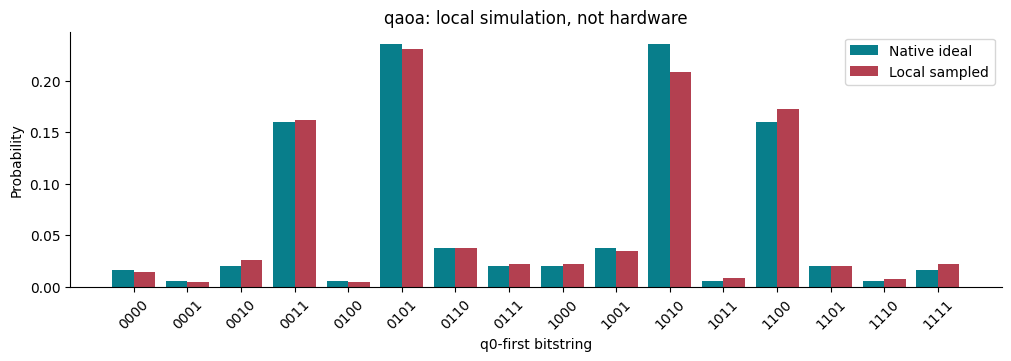

experiment,counts
qaoa,"{""0101"": 236, ""1010"": 213, ""1100"": 177, ""0011"": 166, ""1001"": 35, ""1101"": 21, ""0110"": 38, ""1111"": 23, ""0010"": 27, ""1011"": 9, ""1000"": 23, ""0111"": 23, ""1110"": 8, ""0000"": 15, ""0001"": 5, ""0100"": 5}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- qaoa ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
h q[0];
h q[1];
h q[2];
h q[3];
cx q[0],q[1];
rz(0.52359877559829893) q[1];
cx q[0],q[1];
cx q[0],q[2];
rz(0.26179938779914935) q[2];
cx q[0],q[2];
cx q[0],q[3];
rz(1.0471975511965976) q[3];
cx q[0],q[3];
cx q[1],q[2];
rz(1.0471975511965979) q[2];
cx q[1],q[2];
cx q[2],q[3];
rz(0.52359877559829882) q[3];
cx q[2],q[3];
rz(2.879793265790644) q[0];
u1(-2.879793265790644) q[0];
rx(2.4166097335306098) q[0];
rx(2.4166097335306098) q[1];
rx(2.4166097335306098) q[2];
rx(2.4166097335306098) q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure q[3] -> c[3];



## 8. 结果解释、复做与非目标

最优割权为 6，目标值为 -6。两组名称交换不改变割，不应误报为两个不同业务解。

小图 MaxCut 可执行案例，不等于图优化全部问题族或工业规模求解能力；没有性能或量子加速结论。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/industry/04_combinatorial_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 04_combinatorial_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [Qiskit Optimization MaxCut 定义](https://qiskit-community.github.io/qiskit-optimization/tutorials/06_examples_max_cut_and_tsp.html)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。